In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy.stats import poisson, betabinom, beta as beta_dist, norm
from scipy.special import beta as beta_fn
import scipy.optimize

plt.rcParams.update({
    'figure.dpi': 100,
    'savefig.dpi': 300,
    'font.size': 11,
    'axes.titlesize': 12,
    'axes.labelsize': 11,
})

kmax = 2000
k = np.arange(kmax + 1)

In [2]:
def pk_pl(g):
    p = k[1:] ** (-g)
    return p / p.sum()

def mk_pl_tail_mk(g):
    p = k[1:] ** (-g)
    s1 = (k[1:] * p).sum()
    s0 = p.sum()
    return (s1 + kmax**(2-g)/(g-2)) / (s0 + kmax**(1-g)/(g-1))

def gamma_for_mk(target):
    def f(g):
        return mk_pl_tail_mk(g) - target
    lo, hi = 2.0001, 8.0
    if f(lo) < 0 or f(hi) > 0:
        return None
    return scipy.optimize.brentq(f, lo, hi, xtol=1e-8)

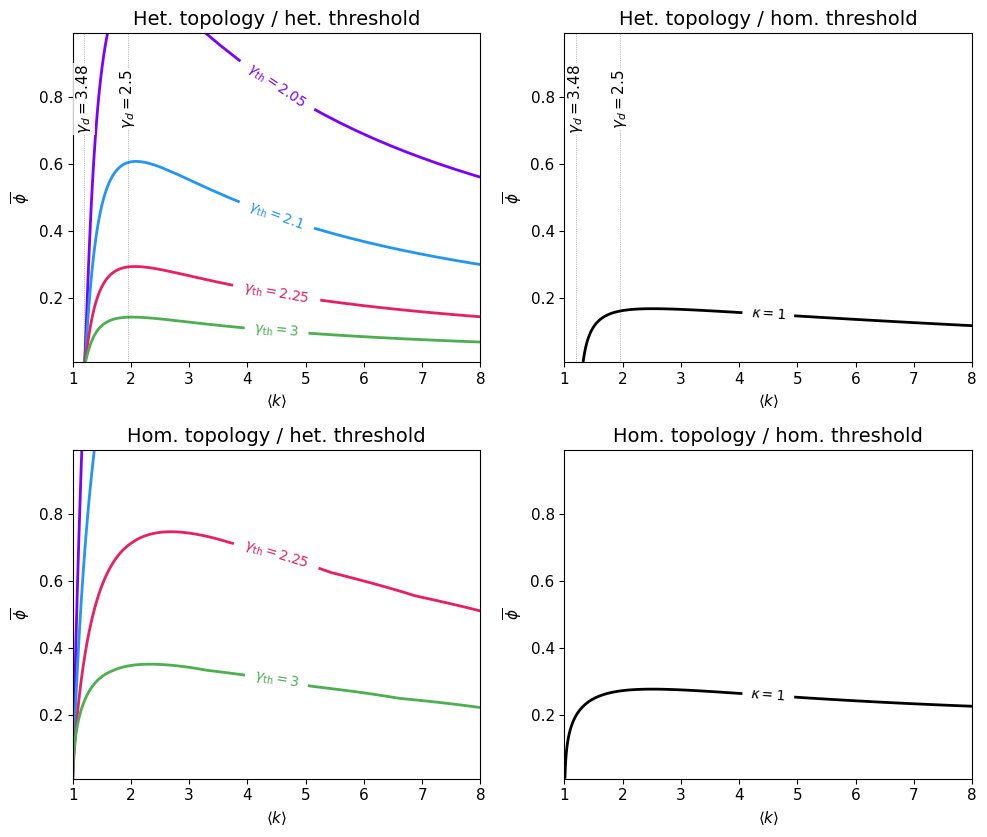

In [3]:
# Figure 1: 2x2 branching ratio — kappa=1 contours at varying gamma_th
# Rows: het. topology (PL) / hom. topology (Poisson)
# Cols: het. threshold (Pareto) / hom. threshold (truncated Gaussian)

sigma_t = 0.1
gamma_ths = [2.05,2.1, 2.25 , 3]
colors = ["#7b00ff",'#2196F3', '#E91E63', '#4CAF50']

gammav = np.linspace(2.01, 3.99, 500)
phiv = np.linspace(0.01, 0.99, 500)
zv = np.linspace(1, 8, 500)

titles = [
    'Het. topology / het. threshold',
    'Het. topology / hom. threshold',
    'Hom. topology / het. threshold',
    'Hom. topology / hom. threshold',
]

# PL degree cache
pl_pk = np.array([pk_pl(g) for g in gammav])
pl_mk = np.array([mk_pl_tail_mk(g) for g in gammav])
pl_w = k[2:] * (k[2:] - 1) * pl_pk[:, 1:]
x_pl = pl_mk[::-1]

# Gaussian threshold CDF (fixed sigma)
mu = phiv[:, None]
Z = norm.cdf(mu / sigma_t)
F_ga = np.zeros((len(phiv), kmax + 1))
xg = 1 / k[None, 1:]
cdf = norm.cdf((xg - mu) / sigma_t)
F_ga[:, 1:] = (cdf - (1 - Z)) / Z

# Poisson degree cache
pk_full = poisson.pmf(k, zv[:, None])
pk_full[:, 0] = 0.0
w_po = k[2:] * (k[2:] - 1) * pk_full[:, 2:]

# PL kappa for Gaussian threshold
K_pl_ga = (pl_w @ F_ga[:, 2:].T).T / pl_mk[None, :]
x_uni = np.linspace(1, 8, 1000)
K_pl_ga_u = np.array([np.interp(x_uni, x_pl, row) for row in K_pl_ga[:, ::-1]])

# Poisson kappa for Gaussian threshold
K_po_ga = (w_po @ F_ga[:, 2:].T / zv[:, None]).T

def find_contour_y_at_x(xv, phiv_arr, K, x_target):
    """Find y (phi) where contour K=1 crosses x=x_target."""
    kidx = np.argmin(np.abs(xv - x_target))
    col = K[:, kidx]
    sign_changes = np.where(np.diff(np.sign(col - 1)))[0]
    if len(sign_changes) == 0:
        return None
    i = sign_changes[0]
    frac = (1 - col[i]) / (col[i+1] - col[i])
    return phiv_arr[i] + frac * (phiv_arr[i+1] - phiv_arr[i])

fig, axs = plt.subplots(2, 2, figsize=(10, 8.5))

for idx, (ax, title) in enumerate(zip(axs.flat, titles)):
    is_pl = idx < 2
    is_pa = idx % 2 == 0

    if is_pa:
        for gth, col in zip(gamma_ths, colors):
            x0 = phiv * (gth - 2) / (gth - 1)
            xk = k[None, :] * x0[:, None]
            F_pa = np.where(xk < 1, 1 - xk ** (gth - 1), 0.0)
            F_pa[:, 0] = 0.0
            if is_pl:
                K = (pl_w @ F_pa[:, 2:].T).T / pl_mk[None, :]
                K_u = np.array([np.interp(x_uni, x_pl, row) for row in K[:, ::-1]])
                cs = ax.contour(x_uni, phiv, K_u, levels=[1.0], colors=[col], linewidths=2)
                yp = find_contour_y_at_x(x_uni, phiv, K_u, 4.5)
            else:
                K = (w_po @ F_pa[:, 2:].T / zv[:, None]).T
                cs = ax.contour(zv, phiv, K, levels=[1.0], colors=[col], linewidths=2)
                yp = find_contour_y_at_x(zv, phiv, K, 4.5)
            if yp is not None:
                ax.clabel(cs, fmt={1.0: f'$\\gamma_{{\\mathrm{{th}}}}={gth}$'},
                          fontsize=10, colors=[col], inline=True, manual=[(4.5, yp)])
    else:
        if is_pl:
            cs = ax.contour(x_uni, phiv, K_pl_ga_u, levels=[1.0], colors=['black'], linewidths=2)
            yp = find_contour_y_at_x(x_uni, phiv, K_pl_ga_u, 4.5)
        else:
            cs = ax.contour(zv, phiv, K_po_ga, levels=[1.0], colors=['black'], linewidths=2)
            yp = find_contour_y_at_x(zv, phiv, K_po_ga, 4.5)
        if yp is not None:
            ax.clabel(cs, fmt={1.0: r'$\kappa=1$'}, fontsize=10, colors=['black'],
                      inline=True, manual=[(4.5, yp)])

    ax.set_xlim(1, 8)
    if is_pl:
        for mk, lab in zip([1.1945, 1.9474], [r'$\gamma_d=3.48$', r'$\gamma_d=2.5$']):
            ax.axvline(mk, color='k', lw=0.5, ls=':', alpha=0.5)
            ax.text(mk, 0.8, lab, transform=ax.get_xaxis_transform(),
                    ha='center', va='center', fontsize=11, color='black',
                    rotation=90, rotation_mode='anchor',
                    bbox=dict(fc='white', ec='none', pad=1, alpha=0.8))
    ax.set_xlabel(r'$\langle k \rangle$')
    ax.set_ylabel(r'$\overline{\phi}$')
    ax.set_title(title, fontsize=14)

fig.tight_layout()
plt.show()

In [4]:
# Fixed-point finding for rho (cascade fraction)
from scipy.stats import binom

kmax_c = 200
kc = np.arange(kmax_c + 1)

def pk_pl_c(g):
    p = kc[1:] ** (-g)
    return np.concatenate([[0], p / p.sum()])

def pk_poi_c(z):
    return poisson.pmf(kc, z)

def build_F(phi_val, thresh, gamma_th, sigma_t):
    """Vectorized F matrix construction."""
    kk = np.arange(kmax_c + 1)[:, None].astype(float)  # (kmax+1, 1)
    mm = np.arange(kmax_c + 1)[None, :].astype(float)  # (1, kmax+1)
    with np.errstate(divide='ignore', invalid='ignore'):
        x = np.where(kk > 0, mm / kk, 0.0)
    x = np.nan_to_num(x, nan=0.0, posinf=0.0)
    if thresh == 'pa':
        x0 = phi_val * (gamma_th - 2) / (gamma_th - 1)
        F_all = np.where((x > x0) & (x > 0), 1 - (np.clip(x0 / np.maximum(x, 1e-30), 0, 1))**(gamma_th - 1), 0.0)
        r0 = 0.0
    elif thresh == 'un':
        F_all = np.where(x >= phi_val, 1.0, 0.0)
        r0 = 0.0
    elif thresh == 'ln':
        F_all = np.where(x > 0, norm.cdf(np.log(np.maximum(x, 1e-30)/phi_val)/sigma_t + sigma_t/2), 0.0)
        r0 = 0.0
    else:
        r0 = norm.cdf(0, loc=phi_val, scale=sigma_t)
        F_all = (norm.cdf(x, loc=phi_val, scale=sigma_t) - r0) / max(1 - r0, 1e-10)
        F_all = np.clip(F_all, 0, None)
    F_ex = F_all.copy()
    F_ex[np.arange(kmax_c+1)[:,None] <= np.arange(kmax_c+1)[None,:]] = 0.0  # zero m>=k
    F_no = F_all.copy()
    F_no[np.arange(kmax_c+1)[:,None] < np.arange(kmax_c+1)[None,:]] = 0.0   # zero m>k
    F_ex[0, :] = 0.0; F_no[0, :] = 0.0
    return F_ex, F_no, r0

def precompute_F_grids(F_ex, F_no, n_scan=500):
    qs = np.linspace(0, 1, n_scan)
    km = len(F_ex)
    G_kq = np.zeros((km, n_scan))
    H_kq = np.zeros((km, n_scan))
    for k_ in range(1, km):
        if F_ex[k_, :k_].max() != 0:
            pmf = binom.pmf(np.arange(k_)[None, :], k_ - 1, qs[:, None])
            G_kq[k_] = (pmf * F_ex[k_, :k_][None, :]).sum(axis=1)
        if F_no[k_, :k_ + 1].max() != 0:
            pmf = binom.pmf(np.arange(k_ + 1)[None, :], k_, qs[:, None])
            H_kq[k_] = (pmf * F_no[k_, :k_ + 1][None, :]).sum(axis=1)
    return qs, G_kq, H_kq

def find_fixed_points(epk, pk, qs, G_kq, H_kq, r0):
    G_grid = epk @ G_kq
    H_grid = pk @ H_kq
    Gprime_grid = np.gradient(G_grid, qs)
    diffs = r0 + (1 - r0) * G_grid - qs
    crossings = []
    if abs(diffs[0]) < 1e-10:
        crossings.append(0.0)
    elif diffs[0] > 1e-12 and diffs[1] < -1e-12:
        frac = -diffs[0] / (diffs[1] - diffs[0])
        crossings.append(frac * qs[1])
    for i in range(1, len(qs) - 1):
        d0, d1 = diffs[i], diffs[i + 1]
        if d0 * d1 < 0:
            frac = -d0 / (d1 - d0)
            crossings.append((1 - frac) * qs[i] + frac * qs[i + 1])
    rhos = [r0 + (1 - r0) * np.interp(q, qs, H_grid) for q in crossings]
    fprimes = [(1 - r0) * np.interp(q, qs, Gprime_grid) for q in crossings]
    return np.array(crossings), np.array(rhos), np.array(fprimes)

def primary_branch(vals, dt, tt, phiv, gamma_th, sigma_t, n_scan=500):
    F_ex, F_no, r0 = build_F(phiv, tt, gamma_th, sigma_t)
    qs, G_kq, H_kq = precompute_F_grids(F_ex, F_no, n_scan)
    pk_fn = pk_pl_c if dt == 'pl' else pk_poi_c
    kk = np.arange(2, kmax_c + 1)
    xs, rs = [], []
    for v in vals:
        pk = pk_fn(v)
        epk = kc * pk / max((kc * pk).sum(), 1e-10)
        xv = mk_pl_tail_mk(v) if dt == 'pl' else v
        if tt == 'pa':
            x0 = phiv * (gamma_th - 2) / (gamma_th - 1)
            F1 = np.array([max(0, 1 - (k0 * x0)**(gamma_th - 1)) if k0 * x0 < 1 else 0.0 for k0 in kk])
        elif tt == 'ga':
            mu_ = phiv; Z_ = norm.cdf(mu_ / sigma_t)
            F1 = np.array([max(0, norm.cdf(1/k0, mu_, sigma_t) - norm.cdf(0, mu_, sigma_t)) / Z_ for k0 in kk])
        elif tt == 'ln':
            F1 = np.array([norm.cdf(np.log(1.0/(k0*phiv))/sigma_t + sigma_t/2) for k0 in kk])
        else:
            F1 = np.array([1.0 if 1.0 / k0 >= phiv else 0.0 for k0 in kk])
        kappa = (epk[kk] * (kk - 1) * F1).sum()
        q_all, rho_all, fp_all = find_fixed_points(epk, pk, qs, G_kq, H_kq, r0)
        sidx = np.where(fp_all < 1.0)[0]
        if len(sidx) == 0:
            continue
        order = np.argsort(rho_all[sidx])
        s_r = rho_all[sidx][order]
        rs.append(s_r[-1] if kappa >= 1 else s_r[0])
        xs.append(xv)
    return np.array(xs), np.array(rs)

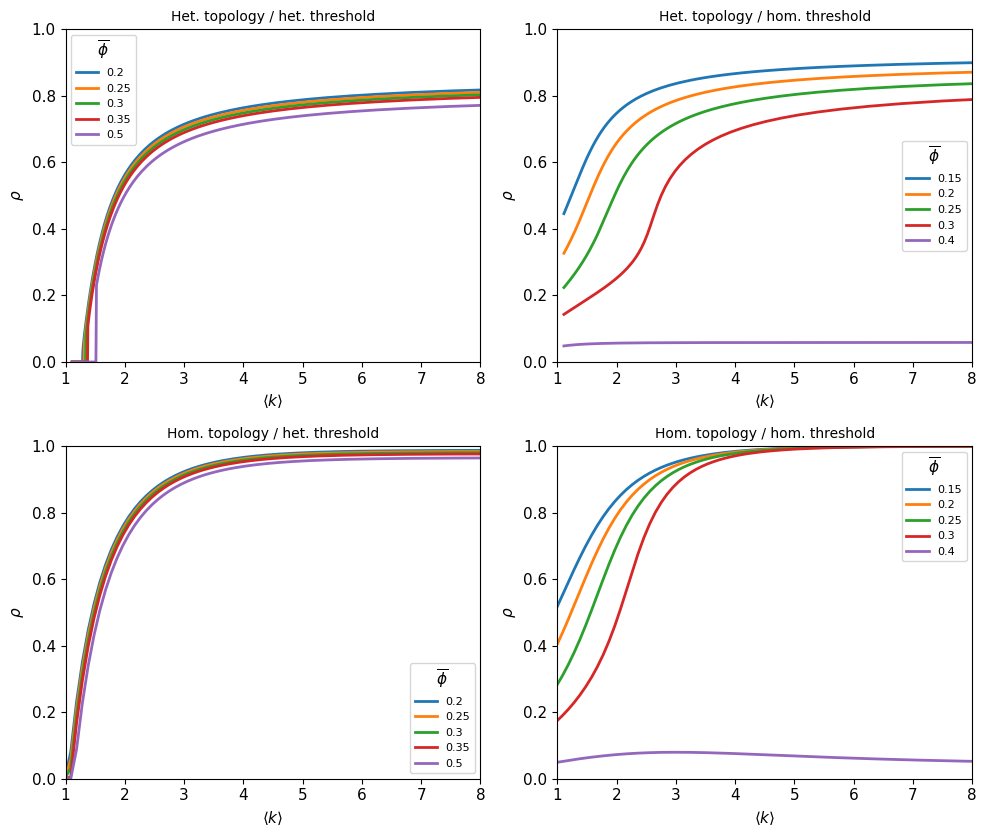

In [5]:
# Figure 2: 2x2 rho bifurcation diagram

gamma_th = 2.1
gammav_b = np.linspace(2.01, 3.99, 200)
zv_b = np.linspace(0.5, 20, 200)
sigma_t = 0.2

phi_vals_pa = [0.20, 0.25, 0.30, 0.35, 0.5]
phi_vals_ga = [0.15, 0.20, 0.25, 0.3, 0.4]

titles_rho = [
    'Het. topology / het. threshold',
    'Het. topology / hom. threshold',
    'Hom. topology / het. threshold',
    'Hom. topology / hom. threshold',
]

# Precompute
rho_data = {}
for dt in ['pl', 'poi']:
    for tt, phis in [('pa', phi_vals_pa), ('ga', phi_vals_ga)]:
        for phif in phis:
            vals = gammav_b if dt == 'pl' else zv_b
            rho_data[(dt, tt, phif)] = primary_branch(vals, dt, tt, phif, gamma_th, sigma_t)

fig, axs = plt.subplots(2, 2, figsize=(10, 8.5))

for ax, dt, tt, title in zip(
    axs.flat,
    ['pl', 'pl', 'poi', 'poi'],
    ['pa', 'ga', 'pa', 'ga'],
    titles_rho,
):
    phis = phi_vals_pa if tt == 'pa' else phi_vals_ga
    for i, phif in enumerate(phis):
        xs, rs = rho_data[(dt, tt, phif)]
        ax.plot(xs, rs, lw=2, label=str(phif))
    ax.set_xlabel(r'$\langle k \rangle$')
    ax.set_ylabel(r'$\rho$')
    ax.set_xlim(1, 8)
    ax.set_ylim(0,1)
    ax.set_title(title, fontsize=10)
    ax.legend(title=r'$\overline{\phi}$', fontsize=8)

fig.tight_layout()
plt.show()

In [ ]:
\
# Visualize the beta distributions: homogeneous vs heterogeneous thresholds and topologies

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# --- Left: Beta threshold distributions ---
ax = axes[0]
x = np.linspace(0.001, 0.999, 500)
threshold_specs = [
    (2,  20, r'$\mathrm{Beta}(2,20)$ — het',   '#E91E63', 2.5),
    (5,  20, r'$\mathrm{Beta}(5,20)$ — het',    '#2196F3', 2.0),
    (10, 20, r'$\mathrm{Beta}(10,20)$ — mild',   '#4CAF50', 2.0),
    (20, 20, r'$\mathrm{Beta}(20,20)$ — hom',    '#7b00ff', 2.0),
]
for a, b, label, col, lw in threshold_specs:
    pdf = beta_dist.pdf(x, a, b)
    ax.plot(x, pdf, color=col, lw=lw, label=label)
ax.set_xlabel(r'$x$')
ax.set_ylabel(r'$f(x)$')
ax.set_title('Threshold distributions')
ax.legend(fontsize=8)
ax.set_xlim(0, 0.8)

# --- Right: Beta-binomial degree distributions ---
ax = axes[1]
kmax_show = 30
kk = np.arange(kmax_show + 1)
# Fix z=5 for all, vary alpha_d
kv_fixed = 5.0
bb_specs = [
    (0.25,   5,      r'$\alpha_d=0.25$ — het',        '#E91E63', 2.5),
    (1.0,   20,      r'$\alpha_d=1$ — het',           '#2196F3', 2.0),
    (5.0,   95,      r'$\alpha_d=5$ — mild',           '#4CAF50', 2.0),
    (1000,  100000,  r'$\alpha_d=10^3$ — hom (Poisson)', '#7b00ff', 2.0),
]
for ad, bd, label, col, lw in bb_specs:
    n_p = max(int(round(kv_fixed * (ad + bd) / ad)), 2)
    pk = betabinom.pmf(kk, n_p, ad, bd)
    ax.plot(kk, pk, 'o-', color=col, lw=lw, ms=4, label=label)
ax.set_xlabel(r'$k$')
ax.set_ylabel(r'$p_k$')
ax.set_title(r'Degree distributions at $\langle k \rangle = 5$')
ax.legend(fontsize=8)
ax.set_xlim(0, kmax_show)

fig.tight_layout()
plt.show()

# Print skewness info
print('Threshold skewness:')
for a, b, label, _, _ in threshold_specs:
    mean = a / (a + b)
    skew = 2*(b-a) / (a+b+2) * ((a+b+1)/(a*b))**0.5
    print(f'  {label}: mean={mean:.3f}, skew={skew:.3f}')
print()
print('Degree skewness (approx):')
for ad, bd, label, _, _ in bb_specs:
    n_p = max(int(round(kv_fixed * (ad + bd) / ad)), 2)
    mean = n_p * ad / (ad + bd)
    var = n_p * ad * bd / ((ad+bd)**2) * (ad+bd+n_p) / (ad+bd+1)
    std = var**0.5
    print(f'  {label}: n={n_p}, mean={mean:.1f}, std={std:.2f}, var/mean={var/mean:.2f}')


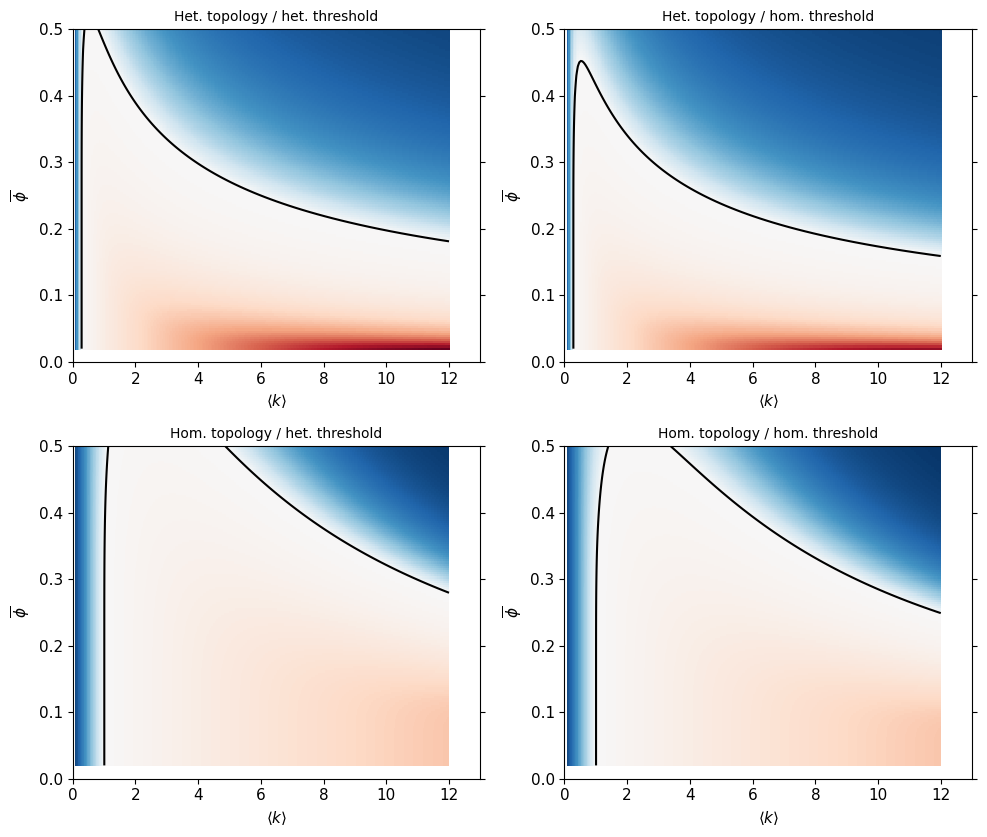

In [6]:
# Figure 3: 2x2 kappa — BB degree × beta threshold
#
# Het: BB(n, alpha_d_het, beta_d) — right-skewed
# Hom: BB(n, alpha_d_hom, beta_d) — symmetric
# Threshold: het_thr Beta(2,20), hom_thr Beta(10,10)

def bb_kappa_panel(n_vals, alpha_d, beta_d, alpha_th, beta_th, phiv, kmax_cap=200):
    kmax_ = min(int(n_vals.max()), kmax_cap)
    kk = np.arange(kmax_ + 1)
    pk = betabinom.pmf(kk[None, :], n_vals[:, None], alpha_d, beta_d)
    pk[:, 0] = 0.0
    mk = (kk * pk).sum(axis=1)
    w = kk[2:] * (kk[2:] - 1) * pk[:, 2:]
    x_axis = n_vals * alpha_d / (alpha_d + beta_d)
    m_th = alpha_th / (alpha_th + beta_th)
    F = beta_dist.cdf(
        np.clip(1.0 / (kk[None, 2:] * phiv[:, None] + 1e-30), 0, 1),
        alpha_th, beta_th)
    K = (w @ F.T / mk[:, None]).T
    return x_axis, K

phiv = np.linspace(0.02, 0.98, 300)

# n chosen so that <k> = n * alpha_d / (alpha_d + beta_d) = kv
kv = np.linspace(0.1, 12, 500)

alpha_d_het, beta_d_het = 0.25, 5
alpha_d_hom, beta_d_hom = 1000, 100000
n_het = np.clip(np.round(kv * (alpha_d_het + beta_d_het) / alpha_d_het).astype(int), 1, None)
n_hom = np.clip(np.round(kv * (alpha_d_hom + beta_d_hom) / alpha_d_hom).astype(int), 1, None)

het_thr  = (15, 20)
hom_thr  = (10, 10)

panels = [
    (n_het, alpha_d_het, beta_d_het, *het_thr, r'Het. topology / het. threshold'),
    (n_het, alpha_d_het, beta_d_het, *hom_thr, r'Het. topology / hom. threshold'),
    (n_hom, alpha_d_hom, beta_d_hom, *het_thr, r'Hom. topology / het. threshold'),
    (n_hom, alpha_d_hom, beta_d_hom, *hom_thr, r'Hom. topology / hom. threshold'),
]

fig, axs = plt.subplots(2, 2, figsize=(10, 8.5))
norm_cmap = TwoSlopeNorm(vcenter=1, vmin=0, vmax=None)

for ax, (nv, ad, bd, at, bt, title) in zip(axs.flat, panels):
    x_axis, K = bb_kappa_panel(nv, ad, bd, at, bt, phiv)
    c = ax.pcolormesh(x_axis, phiv, K, cmap='RdBu_r', norm=norm_cmap, shading='auto')
    ax.contour(x_axis, phiv, K, levels=[1.0], colors='k', linewidths=1.5, antialiased=True)
    ax.set_xlim(0, 13)
    ax.set_ylim(0,0.5)
    ax.set_xlabel(r'$\langle k \rangle$')
    ax.set_ylabel(r'$\overline{\phi}$')
    ax.set_title(title, fontsize=10)
    ax.yaxis.set_ticks_position('both')

fig.tight_layout()
#plt.colorbar(c, ax=list(axs.flat), label=r'$\kappa$')
plt.show()

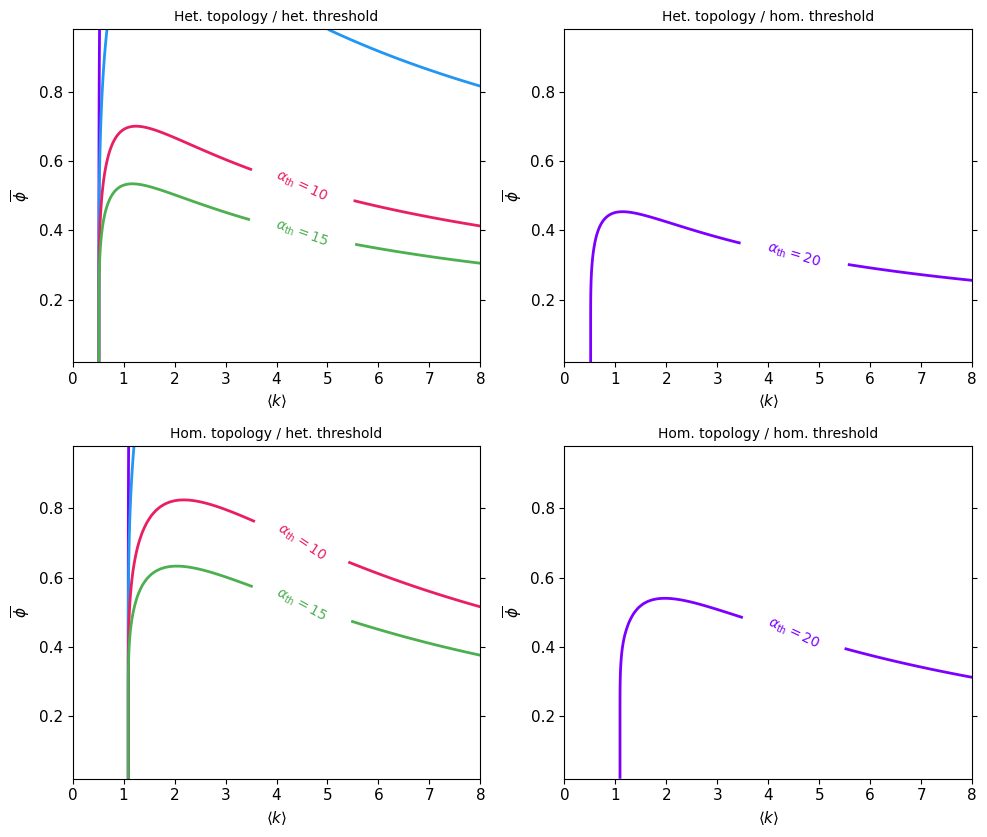

In [7]:
# Figure 3c: 2x2 kappa -- BB degree x Beta threshold, kappa=1 contours
#
# Left col: skewed threshold Beta(a, 20), contours at a = 0.5, 1, 2
# Right col: symmetric threshold Beta(a, a), contours at a = 10
# Rows: het. topology (BB) / hom. topology (BB)

def bb_kappa_panel(n_vals, alpha_d, beta_d, alpha_th, beta_th, phiv, kmax_cap=500):
    kmax_ = min(int(n_vals.max()), kmax_cap)
    kk = np.arange(kmax_ + 1)
    pk = betabinom.pmf(kk[None, :], n_vals[:, None], alpha_d, beta_d)
    pk[:, 0] = 0.0
    mk = (kk * pk).sum(axis=1)
    w = kk[2:] * (kk[2:] - 1) * pk[:, 2:]
    x_axis = n_vals * alpha_d / (alpha_d + beta_d)
    m_th = alpha_th / (alpha_th + beta_th)
    F = beta_dist.cdf(
        np.clip(1.0 / (kk[None, 2:] * phiv[:, None] + 1e-30), 0, 1),
        alpha_th, beta_th)
    K = (w @ F.T / mk[:, None]).T
    return x_axis, K

def find_contour_y_at_x(xv, phiv_arr, K, x_target):
    kidx = np.argmin(np.abs(xv - x_target))
    col = K[:, kidx]
    sign_changes = np.where(np.diff(np.sign(col - 1)))[0]
    if len(sign_changes) == 0:
        return None
    i = sign_changes[0]
    frac = (1 - col[i]) / (col[i+1] - col[i])
    return phiv_arr[i] + frac * (phiv_arr[i+1] - phiv_arr[i])

phiv = np.linspace(0.02, 0.98, 300)
kv = np.linspace(0.1, 12, 500)

alpha_d_het, beta_d_het = 1, 100
alpha_d_hom, beta_d_hom = 10000, 100000
n_het = np.clip(np.round(kv * (alpha_d_het + beta_d_het) / alpha_d_het).astype(int), 1, None)
n_hom = np.clip(np.round(kv * (alpha_d_hom + beta_d_hom) / alpha_d_hom).astype(int), 1, None)

alphas_skew = [2, 5, 10, 15]
beta_th_fixed = 20
alphas_sym = [20]
colors = ["#7b00ff","#2196F3", "#E91E63", "#4CAF50"]

titles = [
    r'Het. topology / het. threshold',
    r'Het. topology / hom. threshold',
    r'Hom. topology / het. threshold',
    r'Hom. topology / hom. threshold',
]

fig, axs = plt.subplots(2, 2, figsize=(10, 8.5))

for idx, (ax, title) in enumerate(zip(axs.flat, titles)):
    is_het = idx < 2
    is_skew = idx % 2 == 0
    nv = n_het if is_het else n_hom
    ad, bd = (alpha_d_het, beta_d_het) if is_het else (alpha_d_hom, beta_d_hom)

    if is_skew:
        for ath, col in zip(alphas_skew, colors):
            x_axis, K = bb_kappa_panel(nv, ad, bd, ath, beta_th_fixed, phiv)
            cs = ax.contour(x_axis, phiv, K, levels=[1.0], colors=[col], linewidths=2)
            yp = find_contour_y_at_x(x_axis, phiv, K, 4.5)
            if yp is not None:
                fmt_str = r"$\alpha_{\mathrm{th}}=" + str(ath) + r"$"
                ax.clabel(cs, fmt={1.0: fmt_str},
                          fontsize=10, colors=[col], inline=True, manual=[(4.5, yp)])
    else:
        for ath, col in zip(alphas_sym, colors):
            x_axis, K = bb_kappa_panel(nv, ad, bd, ath, ath, phiv)
            cs = ax.contour(x_axis, phiv, K, levels=[1.0], colors=[col], linewidths=2)
            yp = find_contour_y_at_x(x_axis, phiv, K, 4.5)
            if yp is not None:
                fmt_str = r"$\alpha_{\mathrm{th}}=" + str(ath) + r"$"
                ax.clabel(cs, fmt={1.0: fmt_str},
                          fontsize=10, colors=[col], inline=True, manual=[(4.5, yp)])

    ax.set_xlim(0, 8)
    ax.set_xlabel(r'$\langle k \rangle$')
    ax.set_ylabel(r'$\overline{\phi}$')
    ax.set_title(title, fontsize=10)
    ax.yaxis.set_ticks_position('both')

fig.tight_layout()
plt.show()

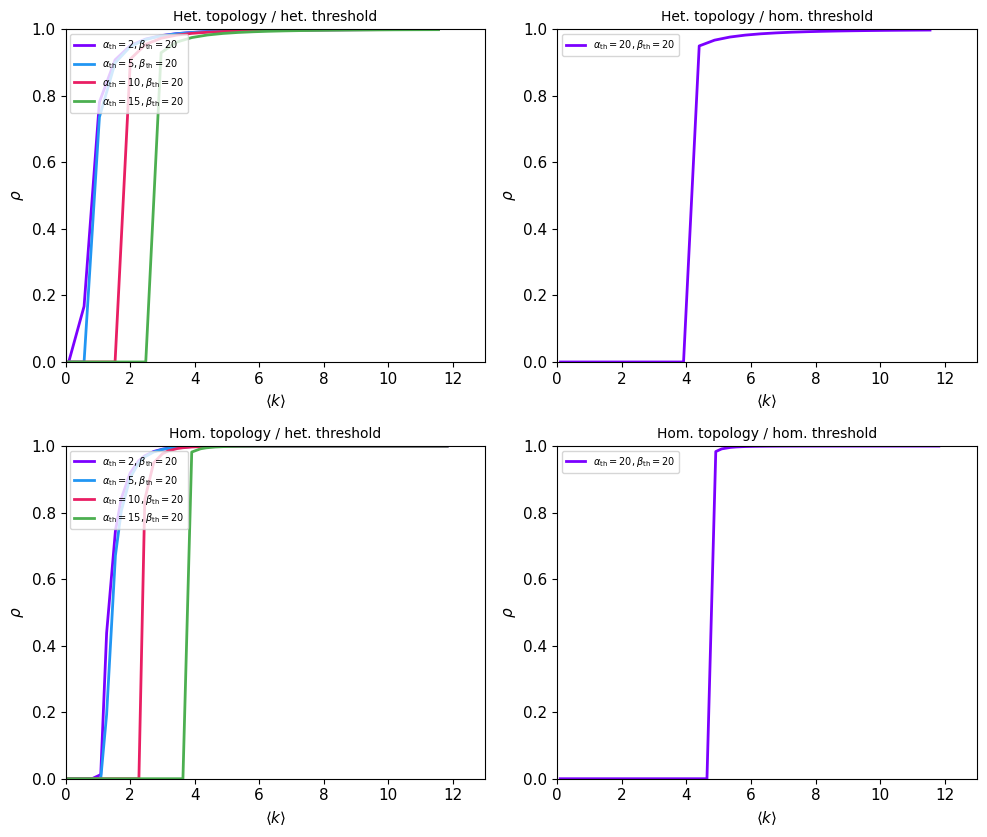

In [8]:
# Figure 3b: 2x2 rho bifurcation — BB degree × Beta threshold
# Curves for different (alpha_th, beta_th) matching kappa contours

kmax_bb = 300
kc_bb = np.arange(kmax_bb + 1)

def bb_rho_sweep(n_vals, alpha_d, beta_d, alpha_th, beta_th, kmax=kmax_bb):
    """Rho vs <k> for BB degree + Beta(alpha_th, beta_th) threshold."""
    kc_ = np.arange(kmax + 1)
    pk = betabinom.pmf(kc_[None, :], n_vals[:, None], alpha_d, beta_d)
    pk[:, 0] = 0.0
    pk = pk / pk.sum(axis=1, keepdims=True)
    mk = (kc_ * pk).sum(axis=1)
    epk = pk * kc_ / mk[:, None]
    x_axis = n_vals * alpha_d / (alpha_d + beta_d)

    kk2d = kc_[:, None].astype(float)
    mm2d = kc_[None, :].astype(float)
    with np.errstate(divide='ignore', invalid='ignore'):
        ratio = np.where(kk2d > 0, mm2d / kk2d, 0.0)
    F_all = beta_dist.cdf(np.clip(ratio, 0, 1), alpha_th, beta_th)
    F_all[0, :] = 0.0
    F_ex = F_all.copy()
    F_ex[np.arange(kmax+1)[:,None] <= np.arange(kmax+1)[None,:]] = 0.0
    F_no = F_all.copy()
    F_no[np.arange(kmax+1)[:,None] < np.arange(kmax+1)[None,:]] = 0.0
    F_ex[0, :] = 0.0; F_no[0, :] = 0.0
    r0 = beta_dist.cdf(0, alpha_th, beta_th)

    n_scan = 2000
    qs = np.linspace(0, 1, n_scan)
    G_kq = np.zeros((kmax + 1, n_scan))
    H_kq = np.zeros((kmax + 1, n_scan))
    for kk_ in range(1, kmax + 1):
        if F_ex[kk_, :kk_].max() > 0:
            pmf = binom.pmf(np.arange(kk_)[None, :], kk_ - 1, qs[:, None])
            G_kq[kk_] = (pmf * F_ex[kk_, :kk_][None, :]).sum(axis=1)
        if F_no[kk_, :kk_ + 1].max() > 0:
            pmf = binom.pmf(np.arange(kk_ + 1)[None, :], kk_, qs[:, None])
            H_kq[kk_] = (pmf * F_no[kk_, :kk_ + 1][None, :]).sum(axis=1)

    rhos = []
    for i, n in enumerate(n_vals):
        G_grid = epk[i] @ G_kq
        H_grid = pk[i] @ H_kq
        q = 0.99
        for _ in range(300):
            gval = np.interp(q, qs, G_grid)
            q_new = r0 + (1 - r0) * gval
            q_new = np.clip(q_new, 0, 1)
            if abs(q_new - q) < 1e-12:
                break
            q = 0.5 * q + 0.5 * q_new
        hval = np.interp(q, qs, H_grid)
        rho = r0 + (1 - r0) * hval
        if rho < 1e-6:
            G0 = G_grid[0]
            kappa0 = (1 - r0) * G0
            if kappa0 > 1.0:
                q_lo, q_hi = 0.0, 1.0
                for _ in range(100):
                    q_mid = 0.5 * (q_lo + q_hi)
                    diff = r0 + (1 - r0) * np.interp(q_mid, qs, G_grid) - q_mid
                    if diff > 0:
                        q_lo = q_mid
                    else:
                        q_hi = q_mid
                q = 0.5 * (q_lo + q_hi)
                hval = np.interp(q, qs, H_grid)
                rho = r0 + (1 - r0) * hval
        rhos.append(rho)
    return x_axis, np.array(rhos)

# Threshold distributions matching kappa contour labels
het_thr_list = [(2, 20), (5, 20), (10, 20), (15, 20)]
hom_thr_list = [(20, 20)]
thr_colors = ["#7b00ff", "#2196F3", "#E91E63", "#4CAF50"]

fig_rho, axs_rho = plt.subplots(2, 2, figsize=(10, 8.5))

rho_panels = [
    (n_het[::20], alpha_d_het, beta_d_het, het_thr_list, r'Het. topology / het. threshold'),
    (n_het[::20], alpha_d_het, beta_d_het, hom_thr_list, r'Het. topology / hom. threshold'),
    (n_hom[::10], alpha_d_hom, beta_d_hom, het_thr_list, r'Hom. topology / het. threshold'),
    (n_hom[::10], alpha_d_hom, beta_d_hom, hom_thr_list, r'Hom. topology / hom. threshold'),
]

for ax, (nv, ad, bd, thr_list, title) in zip(axs_rho.flat, rho_panels):
    for (at, bt), col in zip(thr_list, thr_colors[:len(thr_list)]):
        x_axis, rho = bb_rho_sweep(nv, ad, bd, at, bt)
        ax.plot(x_axis, rho, lw=2, color=col,
                label=rf'$\alpha_{{\mathrm{{th}}}}={at}, \beta_{{\mathrm{{th}}}}={bt}$')
    ax.set_xlabel(r'$\langle k \rangle$')
    ax.set_ylabel(r'$\rho$')
    ax.set_xlim(0, 13)
    ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=7, loc='upper left')

fig_rho.tight_layout()
plt.show()


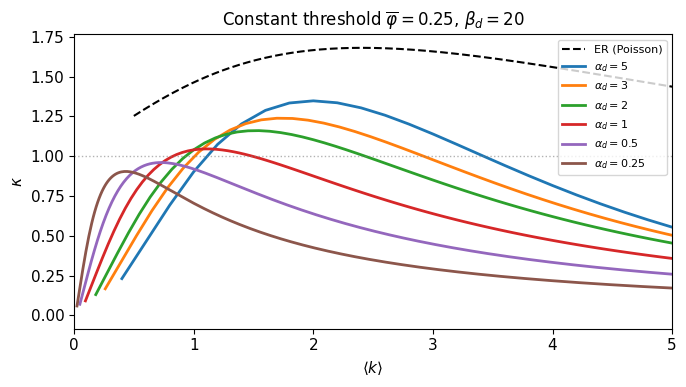

In [9]:
# Figure 4: kappa sweep for BB degree x constant threshold, sweep alpha_d
phi = 0.25
n_max = 5000
n_vals = np.arange(2, n_max + 1)
k_trig = int(1 / phi)

beta_bb = 20.
sets = [
    (5.,   r'$\alpha_d=5$'),
    (3.,   r'$\alpha_d=3$'),
    (2.,   r'$\alpha_d=2$'),
    (1.,   r'$\alpha_d=1$'),
    (0.5,  r'$\alpha_d=0.5$'),
    (0.25, r'$\alpha_d=0.25$'),
]

fig, ax = plt.subplots(figsize=(7, 4))

# ER reference
lam_vals = np.linspace(0.5, 6, 500)
kap_er = []
for lam in lam_vals:
    pk = poisson.pmf(np.arange(k_trig + 1), lam)
    pk[0] = 0.0
    pk = pk / pk.sum()
    ks_er = np.arange(k_trig + 1)
    kap_er.append(np.sum(ks_er[2:] * (ks_er[2:] - 1) * pk[2:]) / lam)
ax.plot(lam_vals, kap_er, lw=1.5, color='black', ls='--', label='ER (Poisson)')

ks = np.arange(n_max + 1)
for a, lab in sets:
    kappas, means = [], []
    for n in n_vals:
        pk = betabinom.pmf(ks[:min(n+1, n_max+1)], n, a, beta_bb)
        mk = (ks[:len(pk)] * pk).sum()
        if mk < 1e-10:
            continue
        kmin = min(k_trig + 1, len(pk))
        w = ks[2:kmin] * (ks[2:kmin] - 1) * pk[2:kmin] / mk
        kappas.append(w.sum())
        means.append(mk)
    ax.plot(means, kappas, lw=2, label=lab)

ax.axhline(1.0, color='gray', ls=':', lw=1, alpha=0.6)
ax.set_xlabel(r'$\langle k \rangle$')
ax.set_ylabel(r'$\kappa$')
ax.set_title(fr'Constant threshold $\overline{{\varphi}}={phi}$, $\beta_d={int(beta_bb)}$')
ax.legend(fontsize=8, loc='upper right')
ax.set_xlim(0, 5)
fig.tight_layout()
plt.show()


In [10]:
from scipy import sparse
from tqdm.notebook import tqdm

def mc_gen_bb_sparse(N, alpha_d, beta_d, z, rng):
    n_param = max(int(np.round(z * (alpha_d + beta_d) / alpha_d)), 2)
    degrees = betabinom.rvs(n_param, alpha_d, beta_d, size=N, random_state=rng)
    stubs = np.repeat(np.arange(N), degrees)
    rng.shuffle(stubs)
    n_edges = len(stubs) // 2
    u = stubs[:2*n_edges:2]; v = stubs[1:2*n_edges:2]
    mask = u != v
    rows = np.concatenate([u[mask], v[mask]])
    cols = np.concatenate([v[mask], u[mask]])
    adj = sparse.csr_matrix((np.ones(len(rows), dtype=np.float32), (rows, cols)), shape=(N, N))
    return adj, degrees

def mc_cascade_sparse(adj, degrees, thresholds, rho0=0.001, rng=None):
    if rng is None:
        rng = np.random.default_rng()
    N = len(thresholds)
    active = np.zeros(N, dtype=bool)
    seeds = rng.choice(N, max(1, int(rho0 * N)), replace=False)
    active[seeds] = True
    k = degrees.astype(np.float32)
    k[k == 0] = 1
    while True:
        m = adj @ active.astype(np.float32)
        to_act = (m / k > thresholds) & (~active) & (degrees > 0)
        if not to_act.any():
            break
        active |= to_act
    return active

def mc_sweep_bb(N, z_vals, alpha_d, beta_d, alpha_th, beta_th,
                rho0=0.001, n_reps=5, seed=42):
    means, stds = [], []
    for z in tqdm(z_vals, desc='z'):
        rhos = []
        for rep in range(n_reps):
            rng = np.random.default_rng(seed + rep)
            adj, deg = mc_gen_bb_sparse(N, alpha_d, beta_d, z, rng)
            thr = beta_dist.rvs(alpha_th, beta_th, size=N, random_state=rng)
            active = mc_cascade_sparse(adj, deg, thr, rho0, rng)
            mask = deg > 0
            rhos.append(active[mask].mean())
        means.append(np.mean(rhos))
        stds.append(np.std(rhos))
    return np.array(means), np.array(stds)

  Het / Beta(5,20)... 

done
  Hom / Beta(5,20)... 

done
  Het / Beta(20,20)... 

done


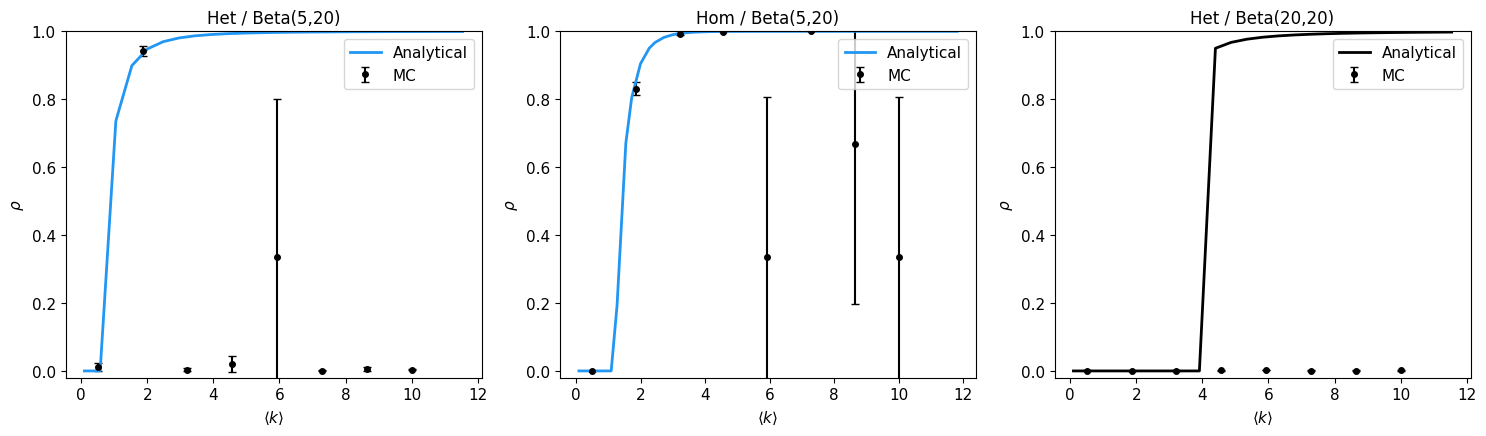

In [11]:
def rho_branch_sweep(n_vals, alpha_d, beta_d, alpha_th, beta_th, kmax=300):
    """Compute rho vs <k> for both fixed-point branches."""
    kc_ = np.arange(kmax + 1)
    pk = betabinom.pmf(kc_[None, :], n_vals[:, None], alpha_d, beta_d)
    pk[:, 0] = 0.0
    pk = pk / pk.sum(axis=1, keepdims=True)
    mk = (kc_ * pk).sum(axis=1)
    epk = pk * kc_ / mk[:, None]
    x_axis = n_vals * alpha_d / (alpha_d + beta_d)

    kk2d = kc_[:, None].astype(float)
    mm2d = kc_[None, :].astype(float)
    with np.errstate(divide='ignore', invalid='ignore'):
        ratio = np.where(kk2d > 0, mm2d / kk2d, 0.0)
    F_all = beta_dist.cdf(np.clip(ratio, 0, 1), alpha_th, beta_th)
    F_all[0, :] = 0.0
    F_ex = F_all.copy()
    F_ex[np.arange(kmax+1)[:,None] <= np.arange(kmax+1)[None,:]] = 0.0
    F_no = F_all.copy()
    F_no[np.arange(kmax+1)[:,None] < np.arange(kmax+1)[None,:]] = 0.0
    F_ex[0, :] = 0.0; F_no[0, :] = 0.0
    r0 = beta_dist.cdf(0, alpha_th, beta_th)

    n_scan = 2000
    qs = np.linspace(0, 1, n_scan)
    G_kq = np.zeros((kmax + 1, n_scan))
    H_kq = np.zeros((kmax + 1, n_scan))
    for kk_ in range(1, kmax + 1):
        if F_ex[kk_, :kk_].max() > 0:
            pmf = binom.pmf(np.arange(kk_)[None, :], kk_ - 1, qs[:, None])
            G_kq[kk_] = (pmf * F_ex[kk_, :kk_][None, :]).sum(axis=1)
        if F_no[kk_, :kk_ + 1].max() > 0:
            pmf = binom.pmf(np.arange(kk_ + 1)[None, :], kk_, qs[:, None])
            H_kq[kk_] = (pmf * F_no[kk_, :kk_ + 1][None, :]).sum(axis=1)

    rho_lo, rho_hi = [], []
    for i in range(len(n_vals)):
        G_grid = epk[i] @ G_kq
        H_grid = pk[i] @ H_kq
        rho_out = []
        for q_init in [0.001, 0.99]:
            q = q_init
            for _ in range(500):
                gval = np.interp(q, qs, G_grid)
                q_new = r0 + (1 - r0) * gval
                q_new = np.clip(q_new, 0, 1)
                if abs(q_new - q) < 1e-12:
                    break
                q = 0.5 * q + 0.5 * q_new
            rho_out.append(r0 + (1 - r0) * np.interp(q, qs, H_grid))
        rho_lo.append(rho_out[0])
        rho_hi.append(rho_out[1])
    return x_axis, np.array(rho_lo), np.array(rho_hi)

N_mc = 10000
z_vals_mc = np.linspace(0.5, 12, 15)
n_reps = 15

test_cases = [
    (alpha_d_het, beta_d_het, 5, 20, r'Het / $\mathrm{Beta}(5,20)$', '#2196F3'),
    (alpha_d_hom, beta_d_hom, 5, 20, r'Hom / $\mathrm{Beta}(5,20)$', '#2196F3'),
    (alpha_d_het, beta_d_het, 20, 20, r'Het / $\mathrm{Beta}(20,20)$', 'k'),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (ad, bd, at, bt, label, col) in zip(axes, test_cases):
    print(f'  {label}...', end=' ', flush=True)
    mc_m, mc_s = mc_sweep_bb(N_mc, z_vals_mc, ad, bd, at, bt, n_reps=n_reps)
    nv_an = n_het[::20] if ad == alpha_d_het else n_hom[::10]
    x_an, rho_lo, rho_hi = rho_branch_sweep(nv_an, ad, bd, at, bt)
    ax.errorbar(z_vals_mc, mc_m, yerr=mc_s, fmt='ko', ms=4, capsize=3, label='MC')
    ax.plot(x_an, rho_lo, '--', lw=1.5, color=col, alpha=0.7, label='Analytical (low branch)')
    ax.plot(x_an, rho_hi, '-', lw=1.5, color=col, alpha=0.7, label='Analytical (high branch)')
    ax.set_xlabel(r'$\langle k \rangle$')
    ax.set_ylabel(r'$\rho$')
    ax.set_title(label)
    ax.legend(fontsize=8)
    ax.set_ylim(-0.02, 1.0)
    print('done')
fig.tight_layout()
plt.show()
